Classsification: Random Forest

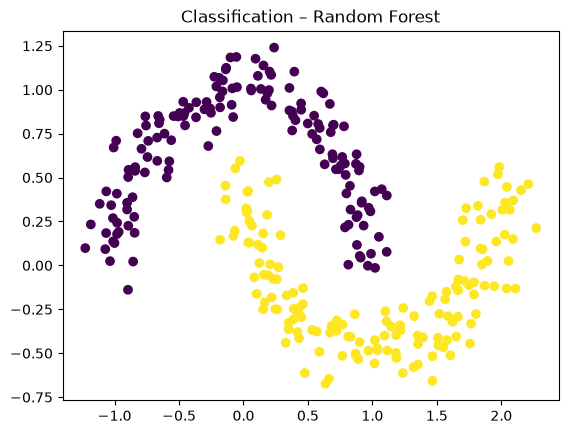

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier

X, y = make_moons(n_samples=300, noise=0.1, random_state=42)

model = RandomForestClassifier(random_state=42)
model.fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=model.predict(X))
plt.title("Classification – Random Forest")
plt.show()

Classifier comparison:

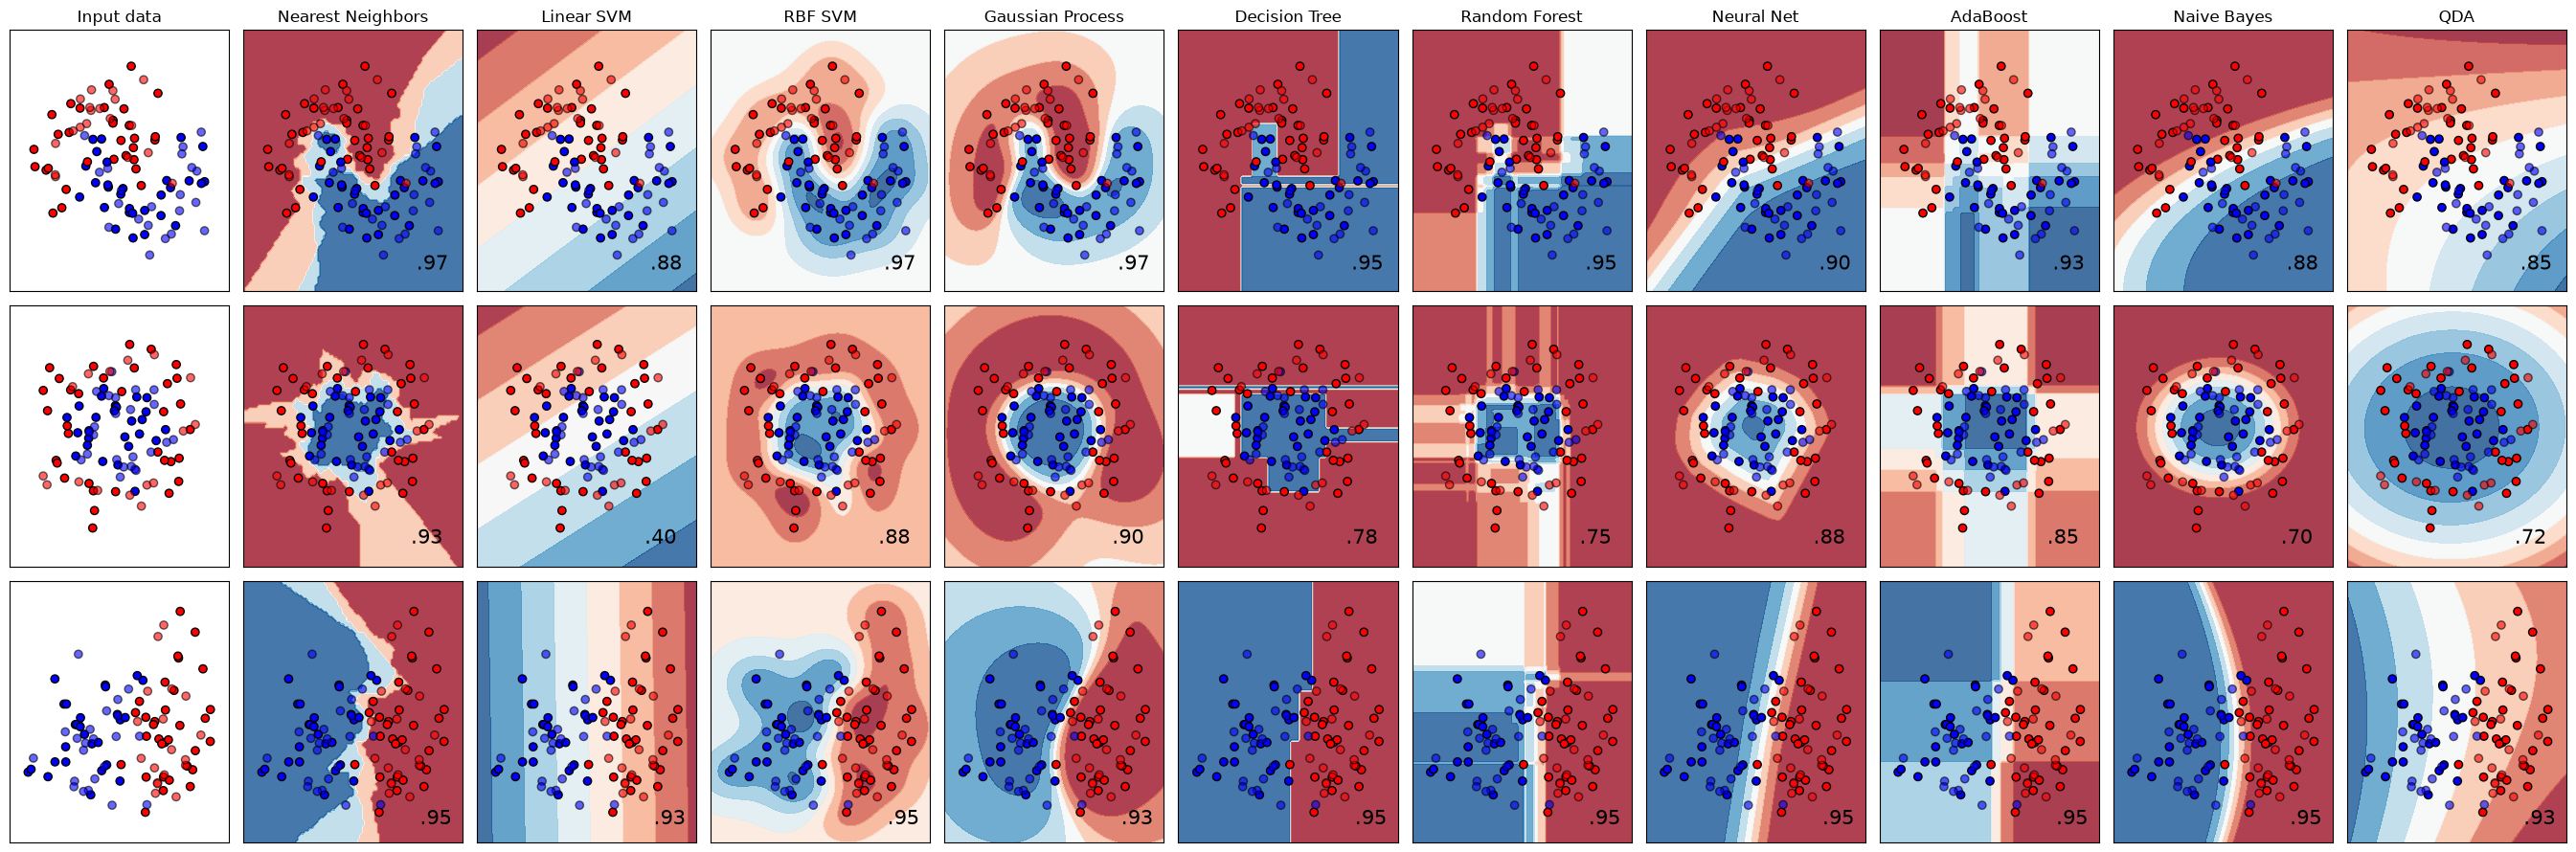

In [2]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles, make_classification, make_moons
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

names = [
    "Nearest Neighbors",
    "Linear SVM",
    "RBF SVM",
    "Gaussian Process",
    "Decision Tree",
    "Random Forest",
    "Neural Net",
    "AdaBoost",
    "Naive Bayes",
    "QDA",
]

classifiers = [
    KNeighborsClassifier(3),
    SVC(kernel="linear", C=0.025, random_state=42),
    SVC(gamma=2, C=1, random_state=42),
    GaussianProcessClassifier(1.0 * RBF(1.0), random_state=42),
    DecisionTreeClassifier(max_depth=5, random_state=42),
    RandomForestClassifier(max_depth=5, n_estimators=10, max_features=1, random_state=42),
    MLPClassifier(alpha=1, max_iter=1000, random_state=42),
    AdaBoostClassifier(random_state=42),
    GaussianNB(),
    QuadraticDiscriminantAnalysis(),
]

X, y = make_classification(n_features=2, n_redundant=0, n_informative=2, random_state=1, n_clusters_per_class=1)
rng = np.random.RandomState(2)
X += 2 * rng.uniform(size=X.shape)
linearly_separable = (X, y)

datasets = [
    make_moons(noise=0.3, random_state=0),
    make_circles(noise=0.2, factor=0.5, random_state=1),
    linearly_separable,
]

figure = plt.figure(figsize=(27, 9))
i = 1
# iterate over datasets
for ds_cnt, ds in enumerate(datasets):
    # preprocess dataset, split into training and test part
    X, y = ds
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    # just plot the dataset first
    cm = plt.cm.RdBu
    cm_bright = ListedColormap(["#FF0000", "#0000FF"])
    ax = plt.subplot(len(datasets), len(classifiers) + 1, i)
    if ds_cnt == 0:
        ax.set_title("Input data")
    # Plot the training points
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright, edgecolors="k")
    # Plot the testing points
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright, alpha=0.6, edgecolors="k")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(())
    ax.set_yticks(())
    i += 1

    # iterate over classifiers
    for name, clf in zip(names, classifiers):
        ax = plt.subplot(len(datasets), len(classifiers) + 1, i)

        clf = make_pipeline(StandardScaler(), clf)
        clf.fit(X_train, y_train)
        score = clf.score(X_test, y_test)
        DecisionBoundaryDisplay.from_estimator(clf, X, cmap=cm, alpha=0.8, ax=ax, eps=0.5)

        # Plot the training points
        ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright, edgecolors="k")
        # Plot the testing points
        ax.scatter(
            X_test[:, 0],
            X_test[:, 1],
            c=y_test,
            cmap=cm_bright,
            edgecolors="k",
            alpha=0.6,
        )

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        ax.set_xticks(())
        ax.set_yticks(())
        if ds_cnt == 0:
            ax.set_title(name)
        ax.text(
            x_max - 0.3,
            y_min + 0.3,
            ("%.2f" % score).lstrip("0"),
            size=15,
            horizontalalignment="right",
        )
        i += 1

plt.tight_layout()
plt.show()

Plot classification probability:

In [3]:
import matplotlib as mpl
from matplotlib import cm
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (
    KBinsDiscretizer,
    PolynomialFeatures,
    SplineTransformer,
)

In [4]:
iris = datasets.load_iris()
X = iris.data[:, 0:2]  # we only take the first two features for visualization
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

In [5]:
classifiers = {
    "Logistic regression\n(C=0.1)": LogisticRegression(C=0.1),
    "Logistic regression\n(C=100)": LogisticRegression(C=100),
    "Gaussian Process": GaussianProcessClassifier(kernel=1.0 * RBF([1.0, 1.0])),
    "Logistic regression\n(RBF features)": make_pipeline(
        Nystroem(kernel="rbf", gamma=5e-1, n_components=50, random_state=1),
        LogisticRegression(C=10),
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "Logistic regression\n(binned features)": make_pipeline(
        KBinsDiscretizer(n_bins=5, quantile_method="averaged_inverted_cdf"),
        PolynomialFeatures(interaction_only=True),
        LogisticRegression(C=10),
    ),
    "Logistic regression\n(spline features)": make_pipeline(
        SplineTransformer(n_knots=5),
        PolynomialFeatures(interaction_only=True),
        LogisticRegression(C=10),
    ),
}

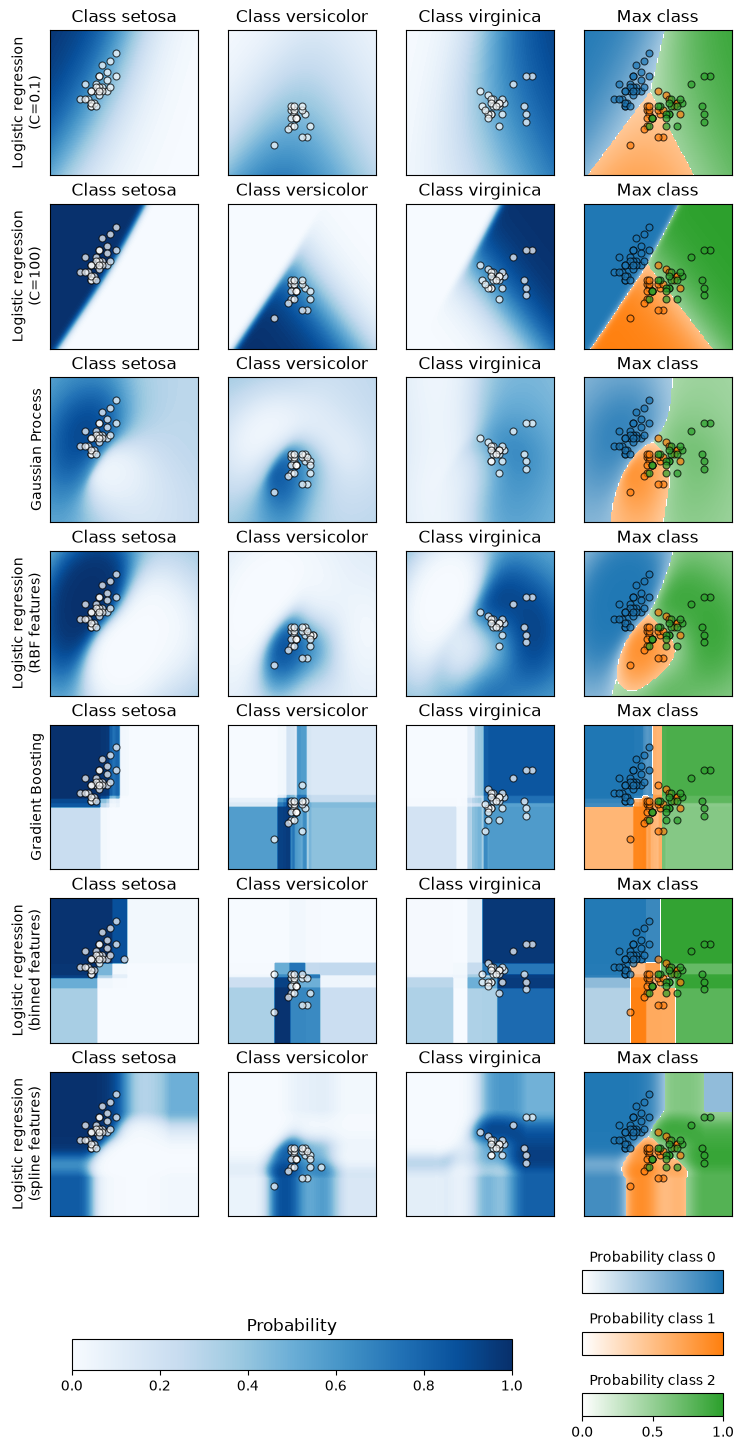

In [6]:
n_classifiers = len(classifiers)
scatter_kwargs = {
    "s": 25,
    "marker": "o",
    "linewidths": 0.8,
    "edgecolor": "k",
    "alpha": 0.7,
}
y_unique = np.unique(y)

# Ensure legend not cut off
mpl.rcParams["savefig.bbox"] = "tight"
fig, axes = plt.subplots(
    nrows=n_classifiers,
    ncols=len(iris.target_names) + 1,
    figsize=(4 * 2.2, n_classifiers * 2.2),
)
evaluation_results = []
levels = 100
for classifier_idx, (name, classifier) in enumerate(classifiers.items()):
    y_pred = classifier.fit(X_train, y_train).predict(X_test)
    y_pred_proba = classifier.predict_proba(X_test)
    accuracy_test = accuracy_score(y_test, y_pred)
    roc_auc_test = roc_auc_score(y_test, y_pred_proba, multi_class="ovr")
    log_loss_test = log_loss(y_test, y_pred_proba)
    evaluation_results.append(
        {
            "name": name.replace("\n", " "),
            "accuracy": accuracy_test,
            "roc_auc": roc_auc_test,
            "log_loss": log_loss_test,
        }
    )
    for label in y_unique:
        # plot the probability estimate provided by the classifier
        disp = DecisionBoundaryDisplay.from_estimator(
            classifier,
            X_train,
            response_method="predict_proba",
            class_of_interest=label,
            ax=axes[classifier_idx, label],
            vmin=0,
            vmax=1,
            cmap="Blues",
            levels=levels,
        )
        axes[classifier_idx, label].set_title(f"Class {iris.target_names[label]}")
        # plot data predicted to belong to given class
        mask_y_pred = y_pred == label
        axes[classifier_idx, label].scatter(X_test[mask_y_pred, 0], X_test[mask_y_pred, 1], c="w", **scatter_kwargs)

        axes[classifier_idx, label].set(xticks=(), yticks=())
    # add column that shows all classes by plotting class with max 'predict_proba'
    max_class_disp = DecisionBoundaryDisplay.from_estimator(
        classifier,
        X_train,
        response_method="predict_proba",
        class_of_interest=None,
        ax=axes[classifier_idx, len(y_unique)],
        vmin=0,
        vmax=1,
        levels=levels,
    )
    for label in y_unique:
        mask_label = y_test == label
        max_col = len(y_unique)
        axes[classifier_idx, max_col].scatter(
            X_test[mask_label, 0],
            X_test[mask_label, 1],
            c=max_class_disp.multiclass_colors_[[label], :],
            **scatter_kwargs,
        )

    axes[classifier_idx, 3].set(xticks=(), yticks=())
    axes[classifier_idx, 3].set_title("Max class")
    axes[classifier_idx, 0].set_ylabel(name)

# colorbar for single class plots
ax_single = fig.add_axes([0.15, 0.01, 0.5, 0.02])
plt.title("Probability")
_ = plt.colorbar(
    cm.ScalarMappable(norm=None, cmap=disp.surface_.cmap),
    cax=ax_single,
    orientation="horizontal",
)

# colorbars for max probability class column
max_class_cmaps = [s.cmap for s in max_class_disp.surface_]

for label in y_unique:
    ax_max = fig.add_axes([0.73, (0.06 - (label * 0.04)), 0.16, 0.015])
    plt.title(f"Probability class {label}", fontsize=10)
    _ = plt.colorbar(
        cm.ScalarMappable(norm=None, cmap=max_class_cmaps[label]),
        cax=ax_max,
        orientation="horizontal",
    )
    if label in (0, 1):
        ax_max.set(xticks=(), yticks=())